# 1) Loading the Taxis Dataset using the following code:

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Display the first five rows
print(df.head())

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

In [30]:
# Display last five rows
print(df.tail())

                  pickup             dropoff  passengers  distance  fare  \
6428 2019-03-31 09:51:53 2019-03-31 09:55:27           1      0.75   4.5   
6429 2019-03-31 17:38:00 2019-03-31 18:34:23           1     18.74  58.0   
6430 2019-03-23 22:55:18 2019-03-23 23:14:25           1      4.14  16.0   
6431 2019-03-04 10:09:25 2019-03-04 10:14:29           1      1.12   6.0   
6432 2019-03-13 19:31:22 2019-03-13 19:48:02           1      3.85  15.0   

       tip  tolls  total  color      payment          pickup_zone  \
6428  1.06    0.0   6.36  green  credit card    East Harlem North   
6429  0.00    0.0  58.80  green  credit card              Jamaica   
6430  0.00    0.0  17.30  green         cash  Crown Heights North   
6431  0.00    0.0   6.80  green  credit card        East New York   
6432  3.36    0.0  20.16  green  credit card          Boerum Hill   

                          dropoff_zone pickup_borough dropoff_borough  
6428              Central Harlem North      Manhattan   

In [31]:
# Display dataset shape
print("Dataset Shape:", df.shape)

Dataset Shape: (6433, 14)


In [32]:
# Display column names
print("Column Names:", df.columns)

Column Names: Index(['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls',
       'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone',
       'pickup_borough', 'dropoff_borough'],
      dtype='object')


In [33]:
# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6389 non-null   object        
 10  pickup_zone      6407 non-null   object        
 11  dropoff_zone     6388 non-null   object        
 12  pickup_borough   6407 non-null   object        
 13  dropoff_borough  6388 non-null   object        
dtypes: datetime64[ns](2), float64(5), int64(

In [34]:
# Statistical summary
print(df.describe())

                              pickup                        dropoff  \
count                           6433                           6433   
mean   2019-03-16 08:31:28.514223616  2019-03-16 08:45:49.491217408   
min              2019-02-28 23:29:03            2019-02-28 23:32:35   
25%              2019-03-08 15:50:34            2019-03-08 16:12:51   
50%              2019-03-15 21:46:58            2019-03-15 22:06:44   
75%              2019-03-23 17:41:38            2019-03-23 17:51:56   
max              2019-03-31 23:43:45            2019-04-01 00:13:58   
std                              NaN                            NaN   

        passengers     distance         fare         tip        tolls  \
count  6433.000000  6433.000000  6433.000000  6433.00000  6433.000000   
mean      1.539251     3.024617    13.091073     1.97922     0.325273   
min       0.000000     0.000000     1.000000     0.00000     0.000000   
25%       1.000000     0.980000     6.500000     0.00000     0.00000

# 2) Handling Missing Values  

# Check for missing values in the dataset and identify columns with missing data.

In [35]:
# Check missing values in each column
print(df.isnull().sum())

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


# Impute missing values using appropriate strategies based on the column type (e.g., using the mean, median, or mode for numerical columns and the mode for categorical columns).  

In [36]:
# Identify columns with missing values
missing_columns = df.columns[df.isnull().any()]

print("Columns with Missing Values:")
print(missing_columns)

Columns with Missing Values:
Index(['payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough',
       'dropoff_borough'],
      dtype='object')


In [37]:
# Fill numerical missing values with median
df['distance'] = df['distance'].fillna(df['distance'].median())

df['fare'] = df['fare'].fillna(df['fare'].median())

df['tip'] = df['tip'].fillna(df['tip'].median())

# Fill categorical missing values with mode
df['pickup_borough'] = df['pickup_borough'].fillna(
    df['pickup_borough'].mode()[0]
)

df['dropoff_borough'] = df['dropoff_borough'].fillna(
    df['dropoff_borough'].mode()[0]
)

df['payment'] = df['payment'].fillna(
    df['payment'].mode()[0]
)

# Remove rows with missing critical pickup timestamps
df = df.dropna(subset=['pickup'])

# Check missing values after cleaning
print(df.isnull().sum())

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment             0
pickup_zone        26
dropoff_zone       45
pickup_borough      0
dropoff_borough     0
dtype: int64


# 3) Visualizations using Matplotlib/Pandas Plot:  

# ★ **Line Chart**  Plot a line chart to visualize the fare over time, using the pickup timestamp as the x-axis and fare as the y-axis. Ensure the pickup column is converted to a datetime format before plotting.

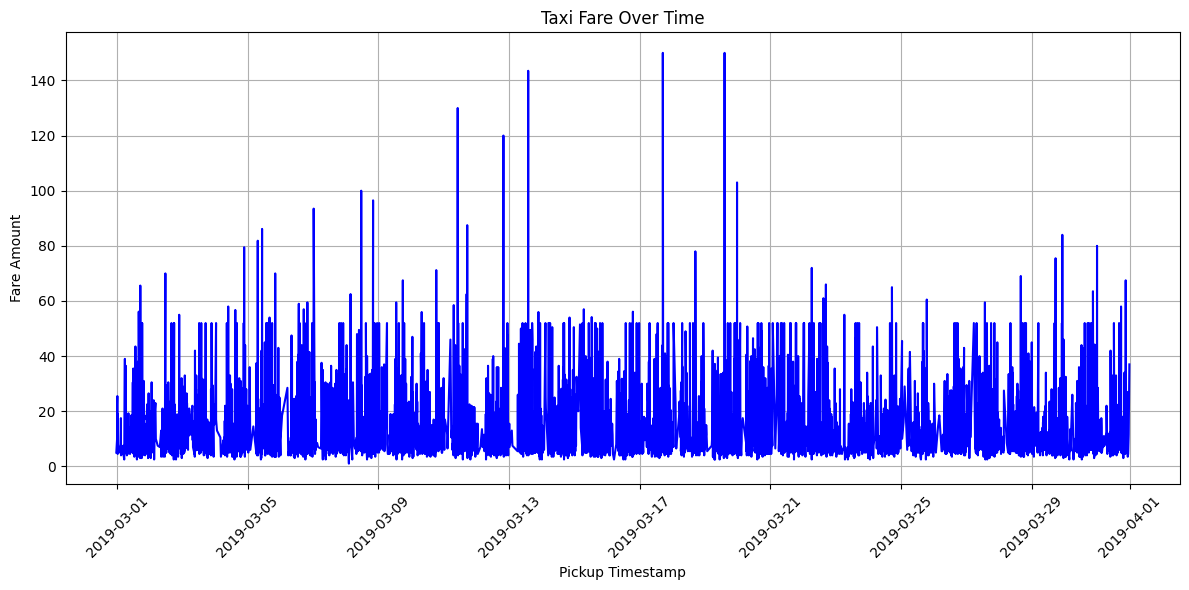

In [38]:
# Convert pickup column into datetime format
df['pickup'] = pd.to_datetime(df['pickup'])

# Sort data by pickup timestamp
df = df.sort_values(by='pickup')

# Create line chart
plt.figure(figsize=(12, 6))

plt.plot(df['pickup'], df['fare'], color='blue')

plt.title('Taxi Fare Over Time')
plt.xlabel('Pickup Timestamp')
plt.ylabel('Fare Amount')

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

# ★ **Bar Chart**  Create a bar chart to show the total fare for each pickup_borough. Group the data by pickup_borough and sum the fare for each group.  

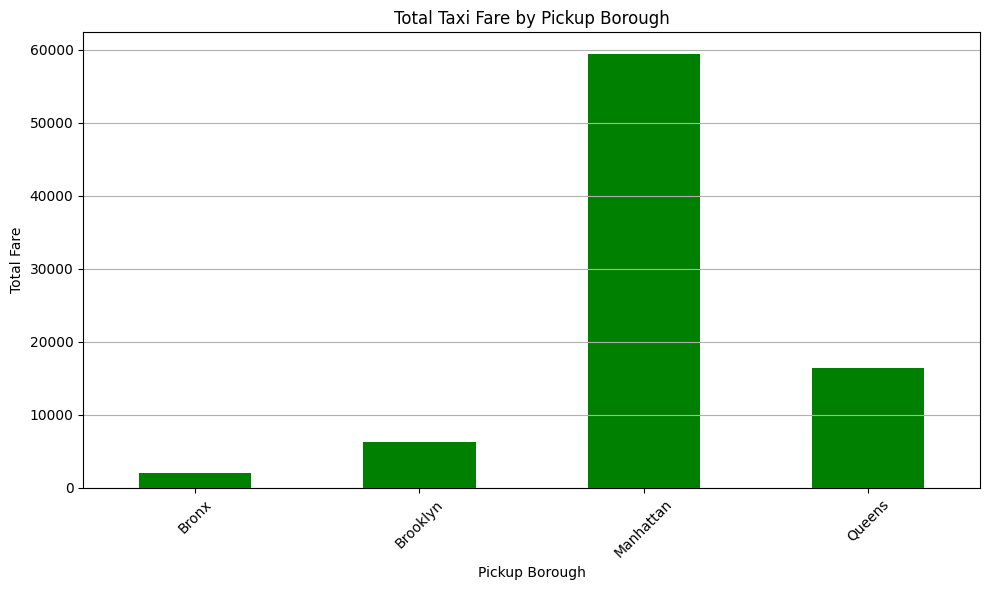

In [39]:
# Group by pickup borough and calculate total fare
borough_fare = df.groupby('pickup_borough')['fare'].sum()

# Create bar chart
plt.figure(figsize=(10, 6))

borough_fare.plot(kind='bar', color='green')

plt.title('Total Taxi Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')

plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()
plt.show()

# ★ **Pie Chart**  Plot a pie chart showing the distribution of trips based on the payment method (credit card, cash, etc.). Each slice should represent the count of trips for a specific payment method.

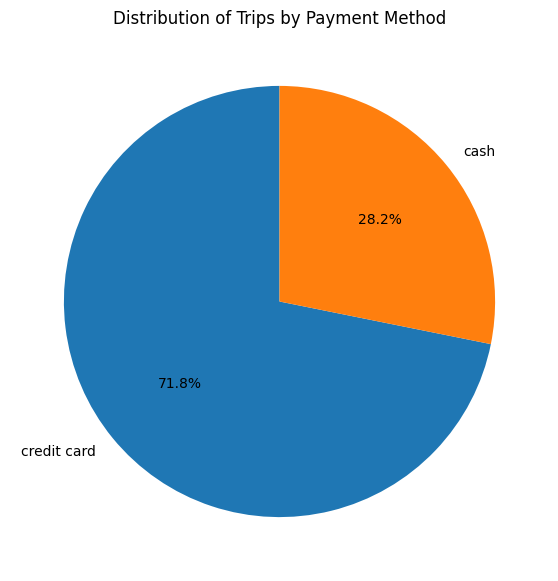

In [40]:
# Count trips by payment method
payment_counts = df['payment'].value_counts()

# Create pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Trips by Payment Method')

plt.show()

# ★ **Histogram** Create a histogram to visualize the distribution of distance. Customize the number of bins for better granularity and ensure the plot is easy to interpret.

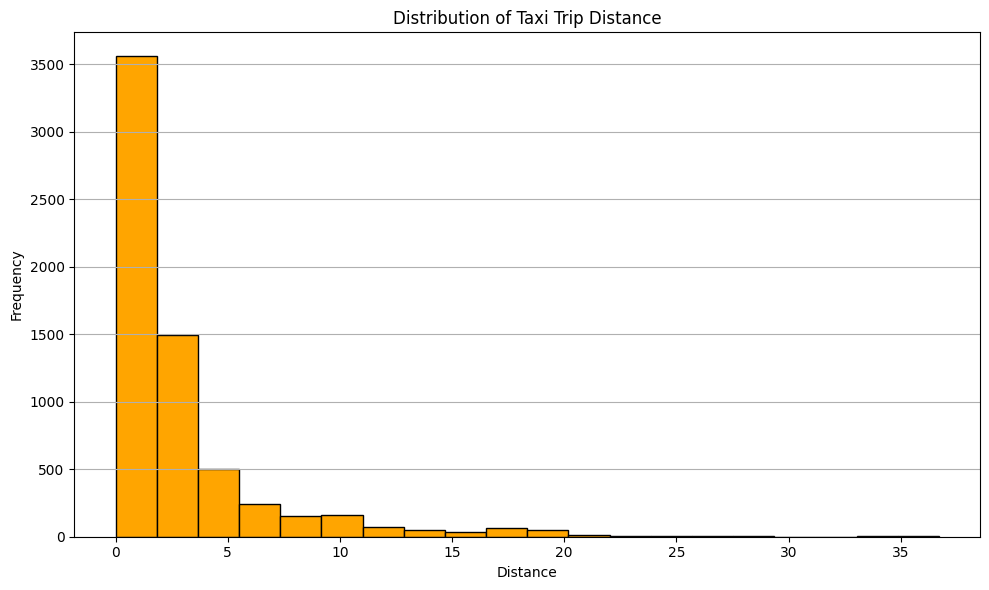

In [41]:
# Create histogram
plt.figure(figsize=(10, 6))

plt.hist(
    df['distance'].dropna(),
    bins=20,
    color='orange',
    edgecolor='black'
)

plt.title('Distribution of Taxi Trip Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')

plt.grid(axis='y')

plt.tight_layout()
plt.show()

# ★ **Box Plot** Plot a box plot to visualize the distribution of tip amounts for each pickup_borough. Use pickup_borough as the categorical axis and tip as the numeric axis.  

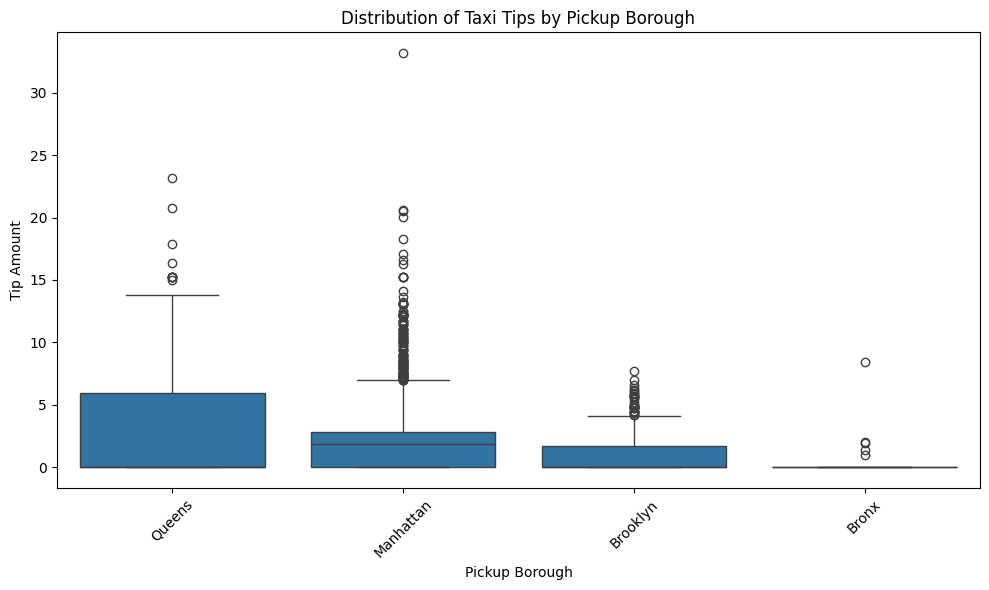

In [42]:
# Create box plot
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='pickup_borough',
    y='tip'
)

plt.title('Distribution of Taxi Tips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Visualizations using Seaborn

# ★ **Count Plot** Create a count plot to visualize the number of trips in each pickup_borough. The x-axis should represent the boroughs, and the y-axis should show the count of trips.

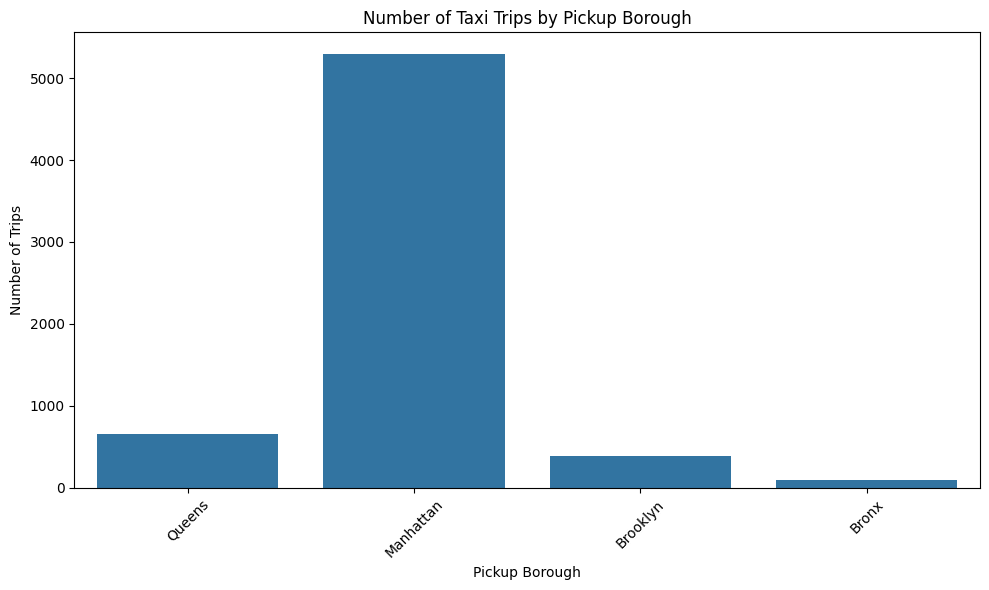

In [43]:
# Create count plot
plt.figure(figsize=(10, 6))

sns.countplot(data=df, x='pickup_borough')

# Add title and labels
plt.title('Number of Taxi Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ★ **Scatter Plot**  Plot a scatter plot to show the relationship between distance and fare. Use distance on the x-axis and fare on the y-axis to visualize any correlation. Color the points based on the pickup_borough to differentiate the trips by their respective boroughs.  

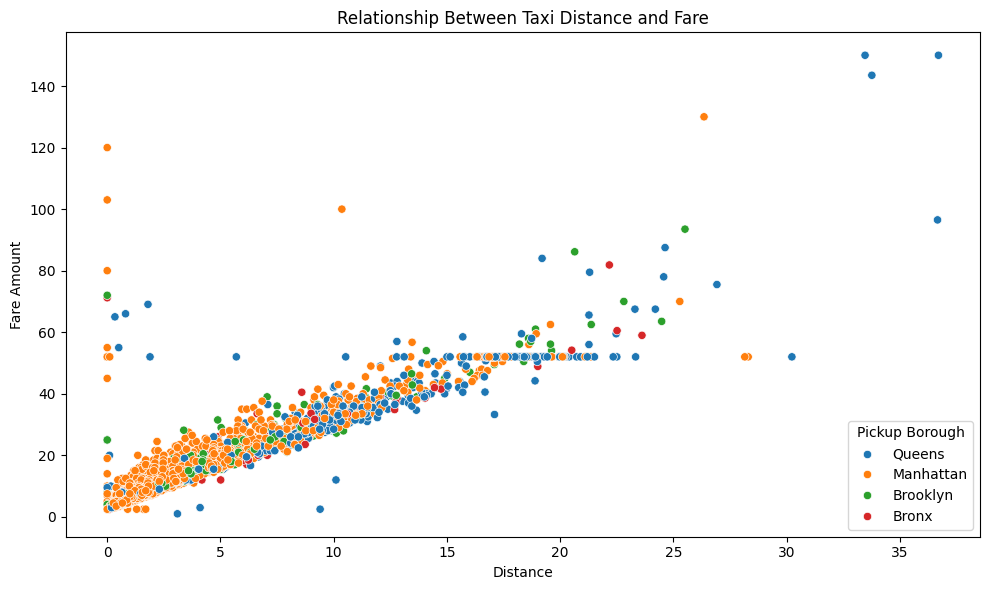

In [44]:
# Create scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough'
)

# Add title and labels
plt.title('Relationship Between Taxi Distance and Fare')
plt.xlabel('Distance')
plt.ylabel('Fare Amount')

plt.legend(title='Pickup Borough')
plt.tight_layout()
plt.show()

# ★ **Heatmap**  Plot a heatmap to visualize the correlation between numerical variables such as distance, fare, tip, tolls, and total. Use a correlation matrix to highlight the relationships.  

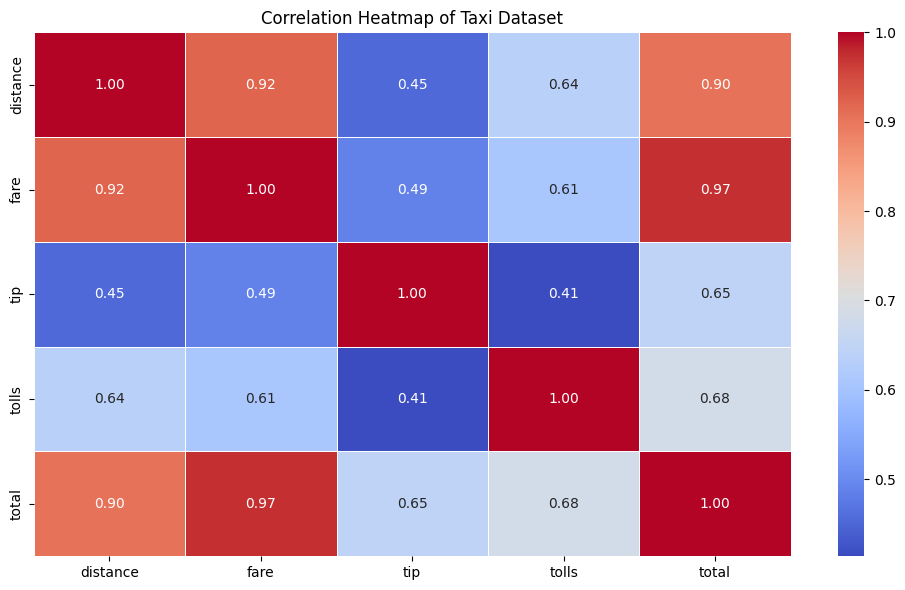

In [45]:
# Select numerical columns
numeric_data = df[['distance', 'fare', 'tip', 'tolls', 'total']]

# Calculate correlation matrix
correlation_matrix = numeric_data.corr()

# Create heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    linewidths=0.5,
    fmt='.2f'
)

# Add title
plt.title('Correlation Heatmap of Taxi Dataset')

plt.tight_layout()
plt.show()

# ★ **Pair Plot** Create a pair plot to visualize the pairwise relationships between distance, fare, tip, and total. Color the data points according to the pickup_zone column. to compare how different zones affect these variables.

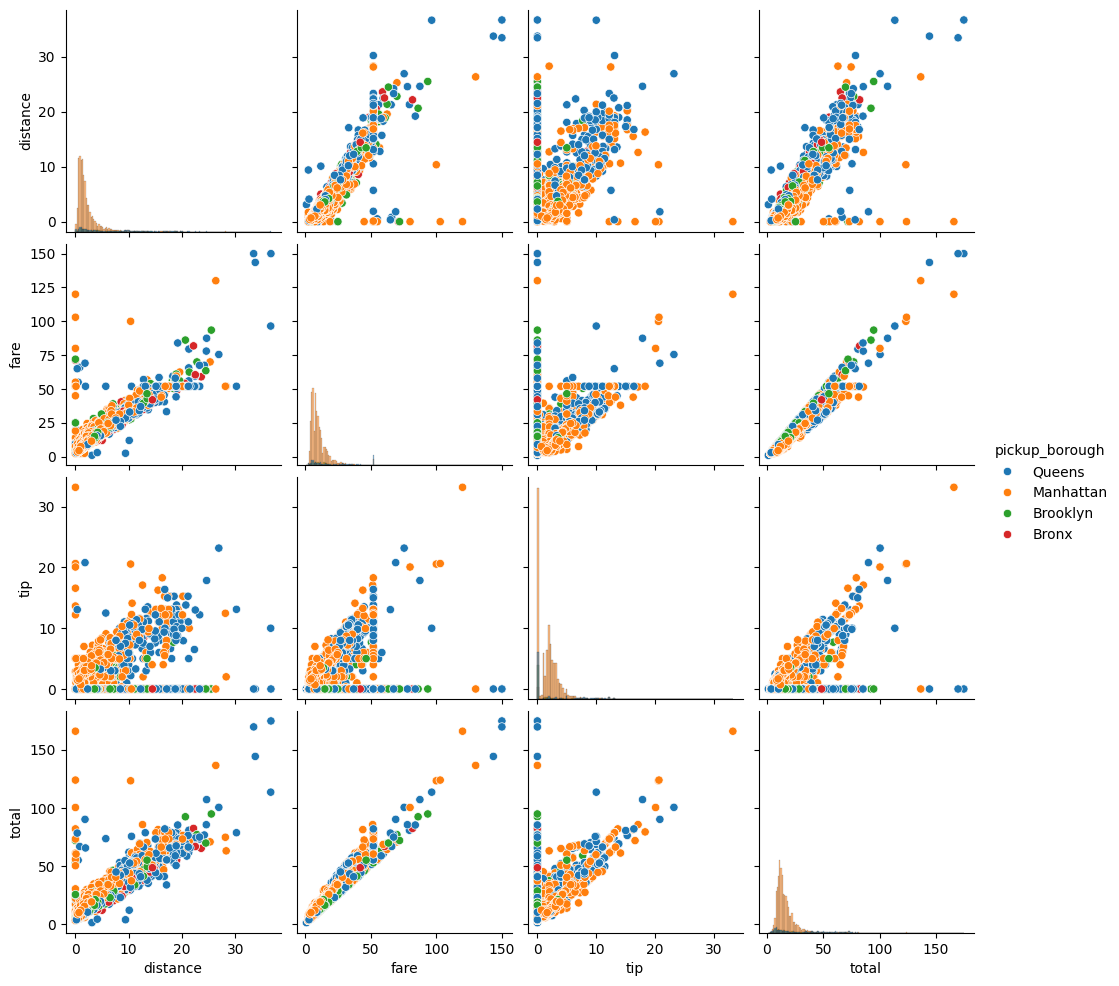

In [46]:
# Select required columns including pickup_borough
pair_data = df[['distance', 'fare', 'tip', 'total', 'pickup_borough']]

# Remove missing values
pair_data = pair_data.dropna()

# Create pair plot using pickup_borough for grouping to avoid performance issues
sns.pairplot(
    pair_data,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='pickup_borough',
    diag_kind='hist'
)

plt.show()

# ★ **Violin Plot**  Plot a violin plot to show the distribution of fare for each payment method. Use the payment method as the categorical axis and fare as the numeric axis to visualize its distribution.

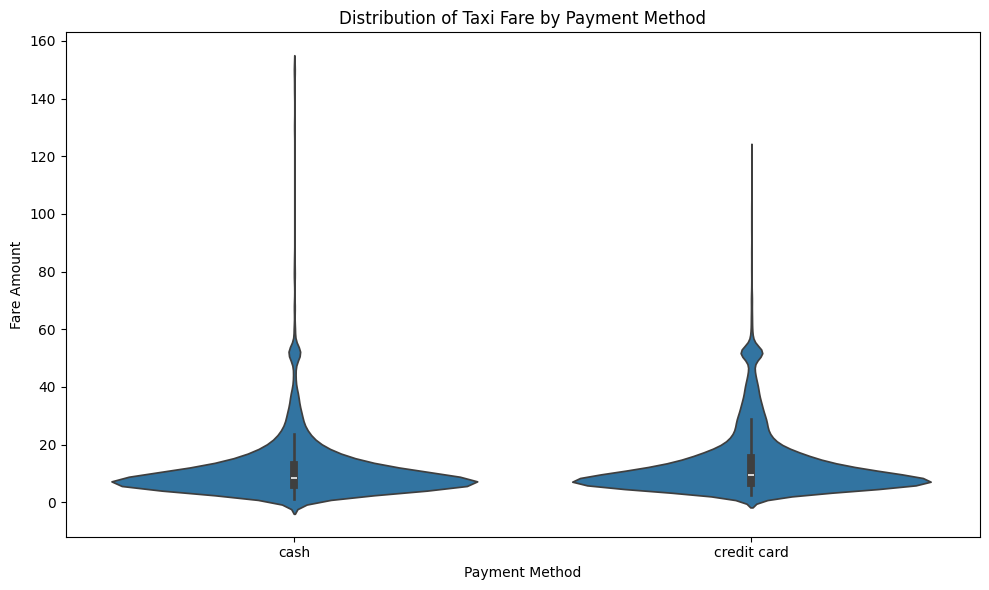

In [47]:
# Create violin plot
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x='payment',
    y='fare'
)

# Add title and labels
plt.title('Distribution of Taxi Fare by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare Amount')

plt.tight_layout()
plt.show()